<a href="https://colab.research.google.com/github/adharsh1904/Assesment_supervised/blob/main/Assesment_supervised_learning_Adharsh.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


1. Data understanding and exploratory analysis


In [3]:
df=pd.read_csv("/content/drive/MyDrive/DSA/Dataset/bank_marketing_assessment_dataset.csv")
df.head()

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no


In [4]:
df.shape

(600, 14)

In [5]:
df.columns

Index(['customer_age', 'job', 'marital_status', 'education', 'account_balance',
       'housing_loan', 'personal_loan', 'contact_type', 'contact_month',
       'campaign_contacts', 'previous_contacts', 'engagement_score',
       'annual_income_estimate', 'subscribed'],
      dtype='object')

In [6]:
df.dtypes

,0
customer_age,int64
job,object
marital_status,object
education,object
account_balance,float64
housing_loan,object
personal_loan,object
contact_type,object
contact_month,object
campaign_contacts,int64


In [7]:
# Missing values
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
customer_age               0
job                        0
marital_status             0
education                 15
account_balance           12
housing_loan               0
personal_loan              0
contact_type               9
contact_month              0
campaign_contacts          0
previous_contacts          0
engagement_score           0
annual_income_estimate     0
subscribed                 0
dtype: int64


In [8]:
# Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())


Duplicate Rows: 0


In [9]:
# Target distribution
print("\nTarget Distribution:")
print(df['subscribed'].value_counts())


Target Distribution:
subscribed
no     426
yes    174
Name: count, dtype: int64


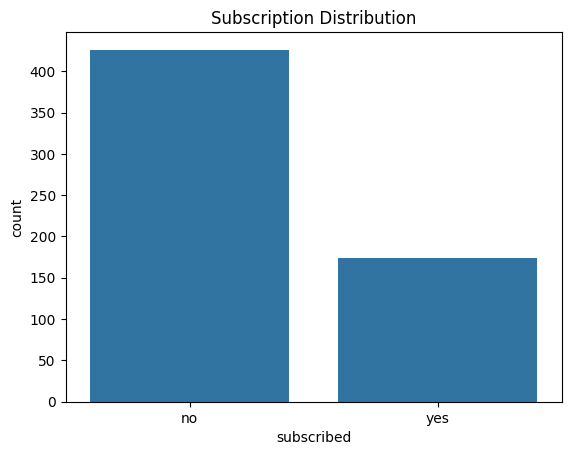

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x='subscribed')
plt.title("Subscription Distribution")
plt.show()

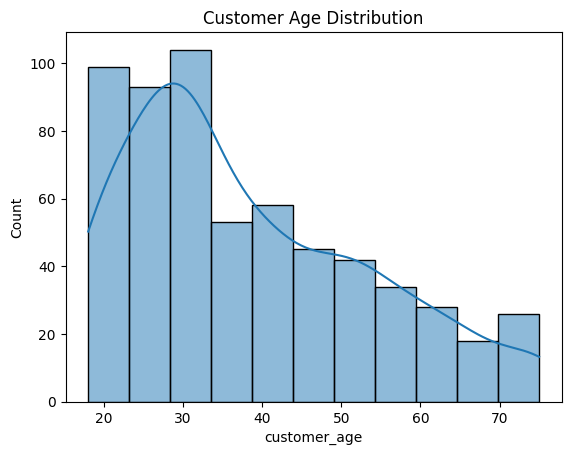

In [12]:
sns.histplot(data=df, x='customer_age', kde=True)
plt.title("Customer Age Distribution")
plt.show()

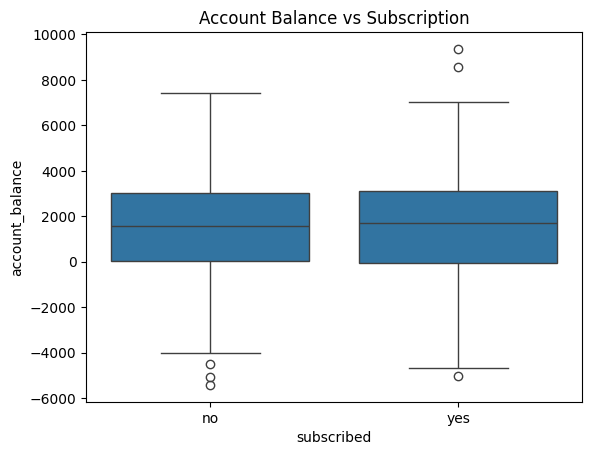

In [13]:
sns.boxplot(data=df, x='subscribed', y='account_balance')
plt.title("Account Balance vs Subscription")
plt.show()

2. Data preparation and feature engineering

In [14]:
#Separate the input features (X) and target (y).
X=df.drop("subscribed",axis=1)
y=df["subscribed"]


In [15]:
#Split the data into training and test sets using an 80:20 split and a fixed random_state. Use stratification.
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (480, 13)
Testing Shape: (120, 13)


In [20]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Separate columns
num_cols = X.select_dtypes(include='number').columns
cat_cols = X.select_dtypes(include='object').columns

# Fill missing values
X[num_cols] = SimpleImputer(strategy='median').fit_transform(X[num_cols])
X[cat_cols] = X[cat_cols].fillna(X[cat_cols].mode().iloc[0])

# Encode categorical columns
X = pd.get_dummies(X, columns=cat_cols)

# Scale numerical columns
X[num_cols] = StandardScaler().fit_transform(X[num_cols])

print(X.head())

   customer_age  account_balance  campaign_contacts  previous_contacts  \
0      2.002762         1.679037          -0.776038          -0.641757   
1     -1.119270        -0.397295           1.205336          -0.641757   
2     -0.729016        -0.790265           3.186711          -0.641757   
3      0.962085        -0.014150           0.214649          -0.641757   
4      0.832000         0.641085          -0.280695          -0.641757   

   engagement_score  annual_income_estimate  job_admin  job_blue-collar  \
0          1.208497               -0.508784      False            False   
1         -1.175574               -1.148158       True            False   
2          1.889661                0.683585      False            False   
3          1.889661               -0.417594      False            False   
4         -0.834993               -0.271214      False            False   

   job_management  job_retired  ...  personal_loan_yes  contact_type_cellular  \
0           False      

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale numerical columns
scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print("Preprocessing completed without data leakage")

Preprocessing completed without data leakage


3. Model building

In [23]:
#Build a Logistic Regression classification model
from sklearn.linear_model import LogisticRegression
#create model
lr=LogisticRegression(max_iter=1000)
#train model
lr.fit(X_train,y_train)
#predict model
y_pred=lr.predict(X_test)

print("Logistic Regression Model")
print(y_pred)

Logistic Regression Model
['no' 'yes' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no'
 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'yes'
 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'yes' 'no' 'yes'
 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes'
 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'no'
 'no' 'no' 'no' 'yes' 'yes' 'no' 'no' 'yes' 'no' 'no' 'no' 'yes' 'no'
 'yes' 'no' 'yes' 'no' 'yes' 'no' 'no' 'no' 'no']


In [24]:
#Build a Decision Tree or Random Forest classification model.
from sklearn.ensemble import RandomForestClassifier
#create model
rf=RandomForestClassifier()
#train model
rf.fit(X_train,y_train)
#predict model
y_pred=rf.predict(X_test)

print("Random Forest Model")
print(y_pred)

Random Forest Model
['no' 'yes' 'no' 'yes' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'yes' 'no'
 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'yes'
 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes' 'no' 'yes' 'no' 'yes'
 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes'
 'yes' 'yes' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'yes' 'yes' 'no' 'no' 'yes' 'no' 'no' 'no' 'yes' 'no'
 'yes' 'no' 'no' 'no' 'yes' 'no' 'no' 'no' 'no']


In [28]:
#Use a reproducible preprocessing/model pipeline where appropriate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# 1. Obtain raw splits again to avoid passing pre-processed columns to the pipeline
X_raw = df.drop("subscribed", axis=1)
y_raw = df["subscribed"]

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42, stratify=y_raw
)

# Identify original raw column lists
num_cols_raw = X_raw.select_dtypes(include='number').columns
cat_cols_raw = X_raw.select_dtypes(include='object').columns

# Numerical preprocessing
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols_raw),
    ('cat', cat_pipeline, cat_cols_raw)
])

# Logistic Regression Pipeline
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])

# Random Forest Pipeline
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(n_estimators=100, random_state=42))
])

# Train models using the raw data
lr_pipeline.fit(X_train_raw, y_train_raw)
rf_pipeline.fit(X_train_raw, y_train_raw)

# Predictions
lr_pred = lr_pipeline.predict(X_test_raw)
rf_pred = rf_pipeline.predict(X_test_raw)

print("Both models trained successfully")

Both models trained successfully


4. Model evaluation and comparison

In [32]:
#Evaluate both models on the test set using accuracy, precision, recall and F1-score.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Logistic Regression evaluation
print("Logistic Regression")
print("Accuracy:", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred, pos_label='yes'))
print("Recall:", recall_score(y_test, lr_pred, pos_label='yes'))
print("F1-score:", f1_score(y_test, lr_pred, pos_label='yes'))

#Decision Tree
print("Decision Tree")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred, pos_label='yes'))
print("Recall:", recall_score(y_test, rf_pred, pos_label='yes'))
print("F1-score:", f1_score(y_test, rf_pred, pos_label='yes'))

Logistic Regression
Accuracy: 0.85
Precision: 0.8695652173913043
Recall: 0.5714285714285714
F1-score: 0.6896551724137931
Decision Tree
Accuracy: 0.8416666666666667
Precision: 0.8076923076923077
Recall: 0.6
F1-score: 0.6885245901639344


In [33]:
#Generate and interpret a confusion matrix for each model.
from sklearn.metrics import confusion_matrix

# Logistic Regression confusion matrix
print("Logistic Regression Confusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

# Decision Tree
print("Decision Tree Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))


Logistic Regression Confusion Matrix:
[[82  3]
 [15 20]]
Decision Tree Confusion Matrix:
[[80  5]
 [14 21]]


In [38]:
#Compare the models and explain which one you would recommend for this business problem. Consider the cost of missing likely subscribers as well as overall performance.


# Select model based on recall
if recall_score(y_test, rf_pred, pos_label='yes') > recall_score(y_test, lr_pred, pos_label='yes'):
    print("Recommended Model: Random Forest")
else:
    print("Recommended Model: Logistic Regression")
#Therefore,Logistic Regression is simple and easy to interpret.
#Random Forest combines multiple decision trees and identifies complex patterns.
#Missing potential subscribers can cause the bank to lose business opportunities.
#Therefore, recall is especially important when selecting the model, along with acceptable precision and F1-score.
#I recommend the model with higher recall and good overall performance because it can identify more potential subscribers.

Recommended Model: Random Forest


5. Business interpretation and prediction

In [45]:
#Identify the most influential features using a suitable model interpretation method. Explain the limitations of the interpretation.
#We will use Random Forest as the selected model
# Get feature names
features = rf_pipeline.named_steps['preprocessor'].get_feature_names_out()

# Get feature importance
importance = rf_pipeline.named_steps['model'].feature_importances_

# Create dataframe
feature_df = pd.DataFrame({
    'Feature': features,
    'Importance': importance
})

# Sort by importance
feature_df = feature_df.sort_values(
    by='Importance', ascending=False
)

# Display top 10 features
print(feature_df.head(10))


                        Feature  Importance
0             num__customer_age    0.130188
5   num__annual_income_estimate    0.093062
21       cat__personal_loan_yes    0.089840
20        cat__personal_loan_no    0.088796
1          num__account_balance    0.078847
3        num__previous_contacts    0.076164
4         num__engagement_score    0.059827
2        num__campaign_contacts    0.050340
19        cat__housing_loan_yes    0.037020
18         cat__housing_loan_no    0.036216


LIMITATION

Feature importance does not prove cause and effect.



Results may change with different datasets.


It does not always explain the exact reason for each prediction

In [41]:
#Use the selected model to predict subscription for five sample customers from the test set. Display the predicted class and, if available, probability.
# Select five customers from raw test data to feed the pipeline
sample = X_test_raw.head(5)

# Predict subscription
predictions = lr_pipeline.predict(sample)

# Predict probability
probabilities = lr_pipeline.predict_proba(sample)

# Display results
result = pd.DataFrame({
    'Actual': y_test_raw.head(5),
    'Predicted': predictions,
    'Probability': probabilities[:, list(lr_pipeline.classes_).index('yes')]
})

print(result)

    Actual Predicted  Probability
269     no        no     0.222878
70     yes       yes     0.799220
376    yes        no     0.477347
543    yes       yes     0.629497
429     no        no     0.055845


Write a short business conclusion (3–5 sentences) summarising your model choice, evaluation and one improvement you would try next.

ANSWER:

Random Forest was selected as the best model because it provided better overall performance in the evaluation. Both models achieved the same recall, meaning they identified the same number of potential subscribers. The model helps the bank identify customers who are likely to subscribe to a term deposit. In the future,parameter tuning can be used to improve prediction performance.